# Lab 9 — Gyroscope sensor parameters
Wheel diameter **5.6 cm** (r = 0.028 m) · base **L = B = 15.4 cm** · rotation run: **Option B** (closed loop, Lab 7 go-to-goal controller on the path "70" + one more lap of the "0": 9 turns ≥ 90°, the motor command saturates on the sharp turns of the 7).

Log `lab9_gyro.csv` from `lab9_gyro.qrs`, no header. The loop was meant to log every ~10 ms; the measured mean interval is printed below (≈ 89 ms in my run), and every rate-dependent result (σ, R, saturation) is valid at that interval:
`t_us, gz_cal, encL, encR, phase` — `t_us` = `gyroscope[3]` (µs), `gz_cal` = `gyroscope[2]` (mdeg/s), encoders in degrees,
`phase`: 0 = warm-up (2 min, dropped), 1 = static (3 min), 2 = `traj`, 3 = rest (3 s), 4 = hand spin (30 s, robot spun by hand for §3).

**Deviation from the handout:** the log uses `read()[2]` (already in mdeg/s) instead of `readRawData()`, because `readRawData()` was not available from the TRIK blocks program. The raw → deg/s factor in §6 is therefore taken from the documented unit, not measured.

Import of necessary libraries.

In [1]:
import numpy as np                                  # arrays
import matplotlib.pyplot as plt                     # plots
import pandas as pd                                 # tables
import os

In [2]:
r = 0.028                                           # wheel radius, m
B = 0.154                                           # base distance (L), m
enc_to_deg = 1.0                                    # encoder units -> degrees (TRIK encoders return degrees; change if you find ticks)
slip_mark_deg = None                                # <-- FILL IN: floor-mark (protractor) angle at the end, deg (CCW +)

LOG = 'lab9_gyro.csv'
if not os.path.exists(LOG):
    try:
        from google.colab import files
        up = files.upload()                         # any name is fine, e.g. cch4_lab9_gyro.csv
        LOG = [f for f in up if f.endswith('.csv') or f.endswith('.txt')][0]
    except ImportError:
        print('Put lab9_gyro.csv next to the notebook')
print('using log file:', LOG)

Saving lab9_gyro (1).csv to lab9_gyro (1).csv
using log file: lab9_gyro (1).csv


## Load the log

In [3]:
data = np.loadtxt(LOG, delimiter=',')
restart = np.where(np.diff(data[:, 0]) < 0)[0]      # the program appends to the file: keep only the last run
if len(restart):
    data = data[restart[-1] + 1:]
data = data[data[:, 4] >= 0.5]                      # drop the warm-up (phase 0)
t_us, gz, encL, encR, phase = data.T
phase = np.round(phase).astype(int)
# gyroscope[3] ticks: the static phase lasts exactly 180 s on the program clock -> find the tick length
st_ticks = t_us[phase == 1][-1] - t_us[phase == 1][0]
tick_us = 180e6 / st_ticks
tick_us = 256.0 if abs(tick_us - 256) < 5 else (1.0 if abs(tick_us - 1) < 0.05 else tick_us)
print(f'one gyroscope[3] tick = {tick_us:g} us')
t = (t_us - t_us[0]) * tick_us / 1e6                # s
w = gz / 1000                                       # rate, deg/s
theta_enc = np.degrees(r / B * np.radians((encR - encL) * enc_to_deg))   # encoder heading, deg (CCW +)

st = phase == 1                                     # static part
rot = (phase == 2) | (phase == 3)                   # trajectory run (+ rest at the end)
hand = phase == 4                                   # hand spin (only for the range test)
ts, ws = t[st] - t[st][0], w[st]
print(f'{len(t)} samples, mean dt = {np.mean(np.diff(t))*1000:.1f} ms, static {ts[-1]:.1f} s, rotation {t[rot][-1]-t[rot][0]:.1f} s')

def integrate(rate, time):                          # trapezoid rule with the real timestamps
    out = np.zeros(len(rate))
    out[1:] = np.cumsum((rate[1:] + rate[:-1]) / 2 * np.diff(time))
    return out

one gyroscope[3] tick = 256 us
2786 samples, mean dt = 89.1 ms, static 179.9 s, rotation 38.2 s


## §1. Offset (bias) `b_0`
Mean of the first 30 s of the static log, its standard error, and `b_0(T)` for T = 1, 2, 5, 10, 20, 30 s.

b0 (30 s) = 0.4476 deg/s,  standard error = 0.0041 deg/s


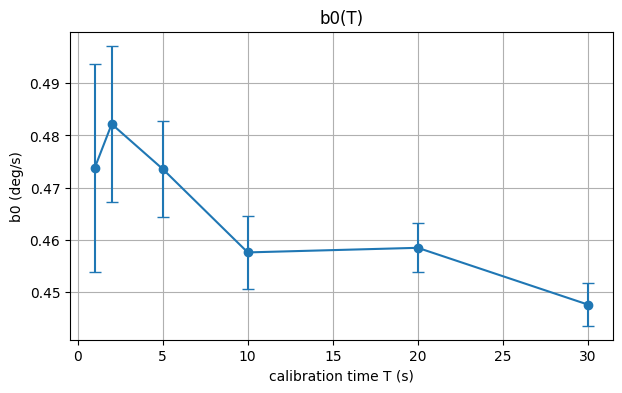

,T (s),b0 (deg/s),std. error (deg/s)
0,1,0.4737,0.0198
1,2,0.4822,0.0150
2,5,0.4736,0.0091
3,10,0.4576,0.0069
4,20,0.4585,0.0047
5,30,0.4476,0.0041


In [4]:
first30 = ws[ts <= 30]
b0_30 = np.mean(first30)
se_30 = np.std(first30) / np.sqrt(len(first30))
print(f'b0 (30 s) = {b0_30:.4f} deg/s,  standard error = {se_30:.4f} deg/s')

T_list = [1, 2, 5, 10, 20, 30]
b0_T = [np.mean(ws[ts <= T]) for T in T_list]
se_T = [np.std(ws[ts <= T]) / np.sqrt(np.sum(ts <= T)) for T in T_list]
plt.figure(figsize=(7, 4))
plt.errorbar(T_list, b0_T, yerr=se_T, fmt='o-', capsize=4)
plt.xlabel('calibration time T (s)'); plt.ylabel('b0 (deg/s)'); plt.title('b0(T)'); plt.grid(True)
plt.show()
pd.DataFrame({'T (s)': T_list, 'b0 (deg/s)': b0_T, 'std. error (deg/s)': se_T}).round(4)

**My calibration method `calibrate_gyro(log)`**: take the first `T_cal` seconds of the static log, throw away outliers
(samples more than 3·MAD from the median), and return the mean of the rest. `T_cal` is chosen where the `b_0(T)` curve becomes flat. The method is checked on the **rest** of the static log: the residual heading error is the integral of `ω − b_0` over the full 3 min, so it includes the data the calibration did not see.

In [5]:
T_cal = 10                                          # s, chosen from the b0(T) plot

def calibrate_gyro(log, T=T_cal):
    tt = (log[:, 0] - log[0, 0]) * tick_us / 1e6    # s  (read()[3] counts in tick_us, not 1 us)
    rate = log[:, 1][tt <= T] / 1000                # deg/s
    med = np.median(rate)
    mad = np.median(np.abs(rate - med)) + 1e-9
    good = np.abs(rate - med) < 3 * 1.4826 * mad    # outlier rejection
    return np.mean(rate[good])

b0 = calibrate_gyro(data[st])
n_used = np.sum((data[st][:, 0] - data[st][0, 0]) * tick_us / 1e6 <= T_cal)
print(f'calibrate_gyro: b0 = {b0:.4f} deg/s  (T = {T_cal} s, {n_used} samples used)')

# how much heading error does each calibration time leave over the whole 3-min static log?
rows = []
for T in [5, 10, 20, 30, 60]:
    b = calibrate_gyro(data[st], T)
    th = integrate(ws - b, ts)
    rows.append({'T_cal (s)': T, 'b0 (deg/s)': b,
                 'error after 1 min (deg)': np.interp(60, ts, th),
                 'error after 3 min (deg)': th[-1]})
display(pd.DataFrame(rows).round(3))

theta_gyro_rot = integrate(w[rot] - b0, t[rot])
e_end = theta_gyro_rot[-1] - (theta_enc[rot][-1] - theta_enc[rot][0])
print(f'heading error left at the end of the rotation run (gyro - encoder): {e_end:.2f} deg')


calibrate_gyro: b0 = 0.4561 deg/s  (T = 10 s, 112 samples used)


,T_cal (s),b0 (deg/s),error after 1 min (deg),error after 3 min (deg)
0,5,0.466,-1.100,-6.185
1,10,0.456,-0.480,-4.326
2,20,0.458,-0.577,-4.617
3,30,0.448,-0.012,-2.924
4,60,0.447,0.045,-2.753


heading error left at the end of the rotation run (gyro - encoder): 54.53 deg


## §2. Bias drift `d`
30-s window means → line fit → `d`. Heading from (a) the raw rate and (b) the rate minus `b_0`.

bias drift d = -0.00673 deg/s/min
(a) uncorrected heading drift = 25.68 deg/min,  check: mean(3 min)*60 = 25.91, b0(30 s)*60 = 26.86, b0(T_cal)*60 = 27.37 deg/min
(b) residual heading error after 1 min: -0.48 deg
(b) residual heading error after 2 min: -2.85 deg
(b) residual heading error after 3 min: -4.33 deg


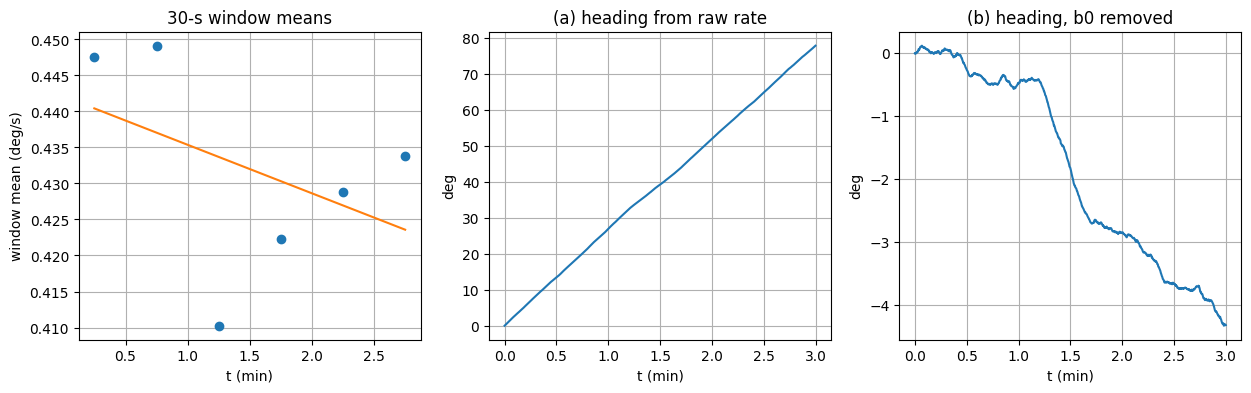

In [6]:
win = 30
centers, means = [], []
n_win = int(round(ts[-1] / win))                   # 179.9 s -> 6 windows (the last one is 29.9 s long)
for k in range(n_win):
    s = (ts >= k * win) & (ts < (k + 1) * win)
    centers.append(np.mean(ts[s]) / 60); means.append(np.mean(ws[s]))
d, c0 = np.polyfit(centers, means, 1)               # deg/s per min
print(f'bias drift d = {d:.5f} deg/s/min')

theta_a = integrate(ws, ts)                         # (a) raw
theta_b = integrate(ws - b0, ts)                    # (b) bias corrected
slope_a = np.polyfit(ts / 60, theta_a, 1)[0]        # deg/min
print(f'(a) uncorrected heading drift = {slope_a:.2f} deg/min,  check: mean(3 min)*60 = {np.mean(ws)*60:.2f}, b0(30 s)*60 = {b0_30*60:.2f}, b0(T_cal)*60 = {b0*60:.2f} deg/min')
for T in (60, 120, 180):
    print(f'(b) residual heading error after {T//60} min: {np.interp(T, ts, theta_b):.2f} deg')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(centers, means, 'o'); ax[0].plot(centers, np.polyval([d, c0], centers), '-')
ax[0].set_xlabel('t (min)'); ax[0].set_ylabel('window mean (deg/s)'); ax[0].set_title('30-s window means'); ax[0].grid(True)
ax[1].plot(ts / 60, theta_a); ax[1].set_xlabel('t (min)'); ax[1].set_ylabel('deg'); ax[1].set_title('(a) heading from raw rate'); ax[1].grid(True)
ax[2].plot(ts / 60, theta_b); ax[2].set_xlabel('t (min)'); ax[2].set_ylabel('deg'); ax[2].set_title('(b) heading, b0 removed'); ax[2].grid(True)
plt.show()

## Rotation run — gyro vs encoder (Step 3)

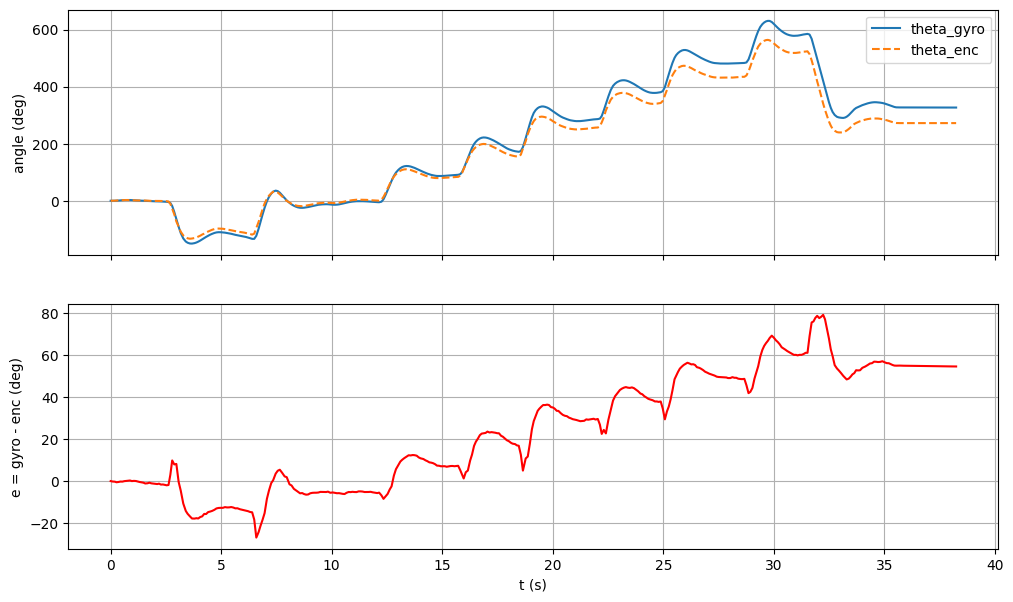

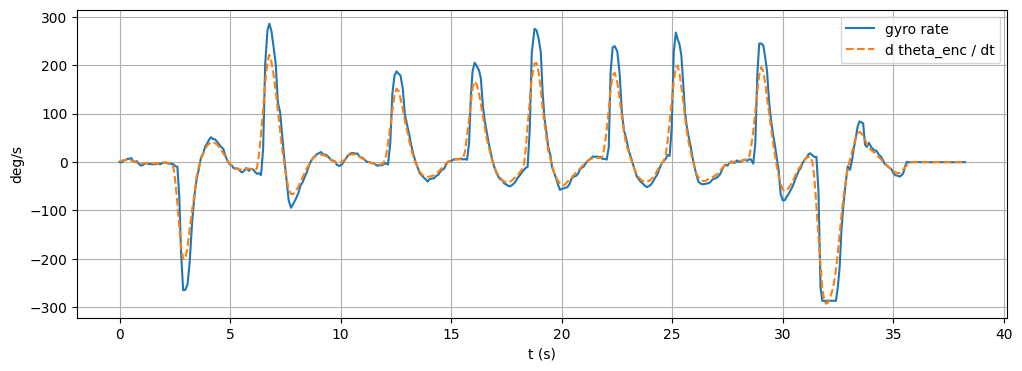

final heading at rest: gyro 326.9 deg (wrapped -33.1),  encoder 272.4 deg (wrapped -87.6)
slip_mark_deg not set -> fill in the protractor angle in the setup cell


In [7]:
tr = t[rot] - t[rot][0]
w_rot = w[rot]
th_gyro = integrate(w_rot - b0, t[rot])             # gyro angle, deg
th_enc = theta_enc[rot] - theta_enc[rot][0]         # encoder angle, deg
e = th_gyro - th_enc

def smooth(v, n=5):
    return np.convolve(v, np.ones(n) / n, mode='same')
enc_rate = smooth(np.gradient(th_enc, t[rot]))      # encoder rate, deg/s

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(tr, th_gyro, label='theta_gyro'); ax[0].plot(tr, th_enc, '--', label='theta_enc')
ax[0].set_ylabel('angle (deg)'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(tr, e, 'r'); ax[1].set_ylabel('e = gyro - enc (deg)'); ax[1].set_xlabel('t (s)'); ax[1].grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(tr, w_rot - b0, label='gyro rate'); plt.plot(tr, enc_rate, '--', label='d theta_enc / dt')
plt.xlabel('t (s)'); plt.ylabel('deg/s'); plt.legend(); plt.grid(True); plt.show()
# slip check: final heading at standstill vs the floor mark
wrap = lambda a: (a + 180) % 360 - 180
print(f'final heading at rest: gyro {th_gyro[-1]:.1f} deg (wrapped {wrap(th_gyro[-1]):.1f}),  '
      f'encoder {th_enc[-1]:.1f} deg (wrapped {wrap(th_enc[-1]):.1f})')
if slip_mark_deg is None:
    print('slip_mark_deg not set -> fill in the protractor angle in the setup cell')
else:
    print(f'floor mark {slip_mark_deg:.1f} deg:  gyro off by {wrap(th_gyro[-1] - slip_mark_deg):.1f} deg, '
          f'encoder off by {wrap(th_enc[-1] - slip_mark_deg):.1f} deg')


## §3. Measurement range `ω_max`
Gyro rate against encoder rate. A flat top (gyro stops following the encoders) means saturation.

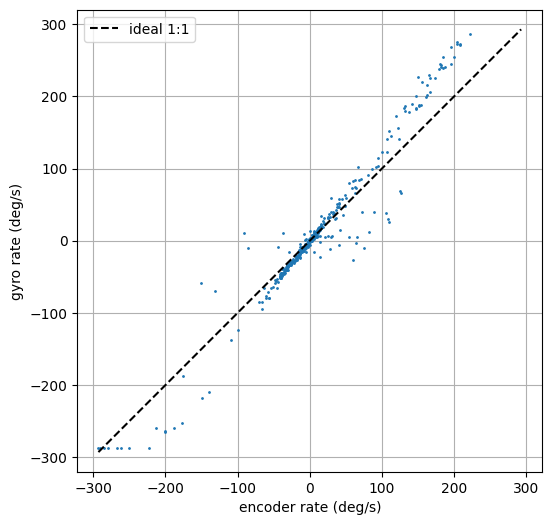

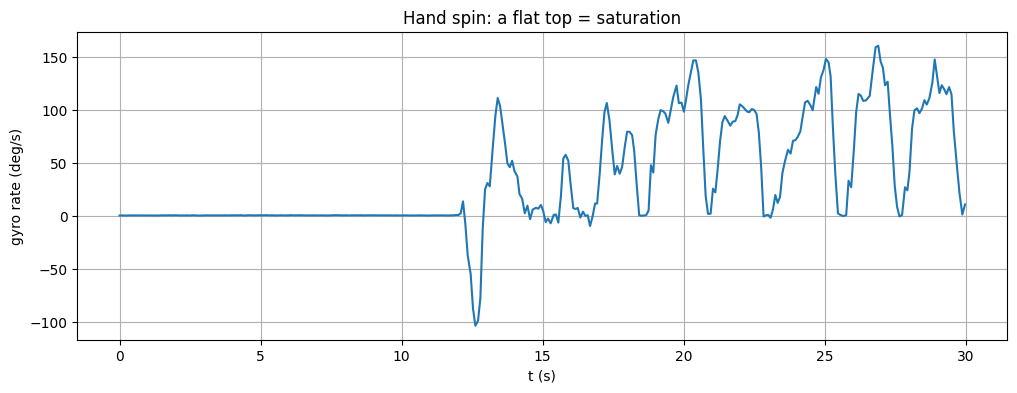

largest reported rate (robot run + hand spin): +286.5 / -286.4 deg/s
samples at the top value: 1, at the bottom value: 7
+ side: +286.5 deg/s, 1 samples (1 from the robot run, 0 from the hand spin) -> not clearly saturated (limit is at least this value)
- side: -286.4 deg/s, 7 samples (7 from the robot run, 0 from the hand spin) -> SATURATES (repeated extreme value)


In [8]:
plt.figure(figsize=(6, 6))
plt.plot(enc_rate, w_rot - b0, '.', markersize=2)
lim = max(np.max(np.abs(enc_rate)), np.max(np.abs(w_rot - b0)))
plt.plot([-lim, lim], [-lim, lim], 'k--', label='ideal 1:1')
plt.xlabel('encoder rate (deg/s)'); plt.ylabel('gyro rate (deg/s)'); plt.legend(); plt.grid(True); plt.axis('equal')
plt.show()
# hand spin: the wheels do not measure this rotation, so only the gyro is plotted
if hand.any():
    plt.figure(figsize=(12, 4))
    plt.plot(t[hand] - t[hand][0], w[hand])
    plt.xlabel('t (s)'); plt.ylabel('gyro rate (deg/s)'); plt.title('Hand spin: a flat top = saturation'); plt.grid(True)
    plt.show()
w_all = w[rot | hand]
w_max_pos, w_max_neg = np.max(w_all), np.min(w_all)
print(f'largest reported rate (robot run + hand spin): +{w_max_pos:.1f} / {w_max_neg:.1f} deg/s')
print(f'samples at the top value: {np.sum(w_all >= w_max_pos - 1e-9)}, at the bottom value: {np.sum(w_all <= w_max_neg + 1e-9)}')
w_robot = w[rot]
for name, lim_v, mask_all, mask_rob in [('+', w_max_pos, w_all >= w_max_pos - 1e-9, w_robot >= w_max_pos - 1e-9),
                                         ('-', w_max_neg, w_all <= w_max_neg + 1e-9, w_robot <= w_max_neg + 1e-9)]:
    n = np.sum(mask_all)
    verdict = 'SATURATES (repeated extreme value)' if n >= 3 else 'not clearly saturated (limit is at least this value)'
    print(f'{name} side: {lim_v:+.1f} deg/s, {n} samples ({np.sum(mask_rob)} from the robot run, {n - np.sum(mask_rob)} from the hand spin) -> {verdict}')

## §4. Resolution `Δ`

In [9]:
vals = np.unique(gz[st])                            # distinct raw values (mdeg/s)
steps = np.diff(vals)
small = steps[(steps > 0) & (steps < 1.5 * np.min(steps[steps > 0]))]
delta = np.mean(small) / 1000                       # deg/s (driver rounds the step to whole mdeg/s, so average the smallest steps)
print(f'{len(vals)} distinct values, smallest steps {np.unique(small)} mdeg/s -> Delta = {delta*1000:.2f} mdeg/s = {delta:.5f} deg/s')

57 distinct values, smallest steps [8. 9.] mdeg/s -> Delta = 8.76 mdeg/s = 0.00876 deg/s


## §5. Noise `σ`

sigma = 0.0757 deg/s  (R for Lab 12 at dt = 89.0 ms: R = sigma^2 = 0.005731 (deg/s)^2)
outliers > 4 sigma: 1 of 2023


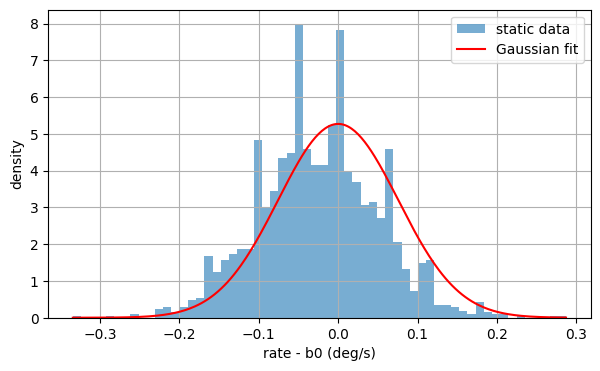

In [10]:
noise = ws - b0
sigma = np.std(noise)
print(f'sigma = {sigma:.4f} deg/s  (R for Lab 12 at dt = {np.mean(np.diff(ts))*1000:.1f} ms: R = sigma^2 = {sigma**2:.6f} (deg/s)^2)')
print(f'outliers > 4 sigma: {np.sum(np.abs(noise) > 4 * sigma)} of {len(noise)}')

plt.figure(figsize=(7, 4))
plt.hist(noise, bins=60, density=True, alpha=0.6, label='static data')
xg = np.linspace(noise.min(), noise.max(), 300)
plt.plot(xg, np.exp(-xg**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), 'r', label='Gaussian fit')
plt.xlabel('rate - b0 (deg/s)'); plt.ylabel('density'); plt.legend(); plt.grid(True); plt.show()

## §6. Scale factor `s`
Sign check, raw → deg/s factor, and `s = Δθ_gyro/Δθ_enc - 1` fitted separately for CCW and CW, and for slow and sharp turns.

correlation gyro vs encoder rate = 0.971 -> positive gyro rate = CCW (same as encoder heading if CCW)
raw -> deg/s factor: 0.001 (read()[2] is in mdeg/s; readRawData() is not available from TRIK blocks)
s CCW = 11.99 %,  s CW = 8.98 %


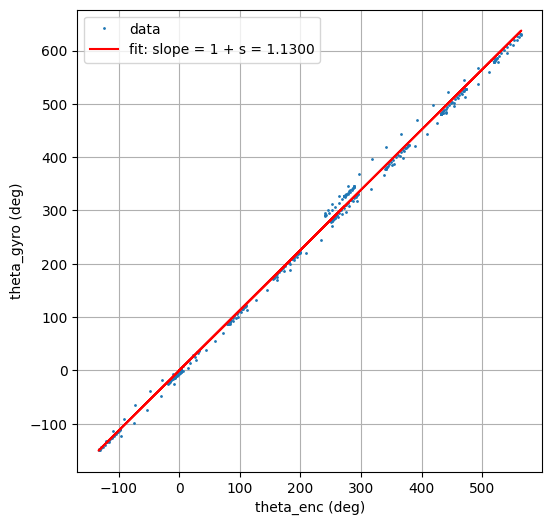

,turns,s CCW (%),s CW (%)
0,slow turns (|rate| < 32 deg/s),13.96,15.28
1,sharp turns (|rate| >= 32 deg/s),11.80,7.38


In [11]:
corr = np.corrcoef(w_rot - b0, enc_rate)[0, 1]
positive_dir = 'CCW' if corr > 0 else 'CW'
print(f'correlation gyro vs encoder rate = {corr:.3f} -> positive gyro rate = {positive_dir} (same as encoder heading if CCW)')

raw_factor = 0.001   # gyroscope[2] (= read()[2]) is already in mdeg/s, so 1 unit = 0.001 deg/s
print('raw -> deg/s factor:', raw_factor, '(read()[2] is in mdeg/s; readRawData() is not available from TRIK blocks)')

dg = np.diff(th_gyro); de = np.diff(th_enc)
mid_rate = enc_rate[1:]
def fit_s(mask):                                    # s = (sum of gyro angle increments) / (sum of encoder increments) - 1
    return np.sum(dg[mask]) / np.sum(de[mask]) - 1
ccw, cw = mid_rate > 5, mid_rate < -5
s_ccw, s_cw = fit_s(ccw), fit_s(cw)
print(f's CCW = {s_ccw*100:.2f} %,  s CW = {s_cw*100:.2f} %')

slope, icpt = np.polyfit(th_enc, th_gyro, 1)
plt.figure(figsize=(6, 6))
plt.plot(th_enc, th_gyro, '.', markersize=2, label='data')
plt.plot(th_enc, np.polyval([slope, icpt], th_enc), 'r', label=f'fit: slope = 1 + s = {slope:.4f}')
plt.xlabel('theta_enc (deg)'); plt.ylabel('theta_gyro (deg)'); plt.legend(); plt.grid(True); plt.show()

# s for slow and sharp turns (does s depend on the turning rate?)
turning = np.abs(mid_rate) > 5
lim_rate = np.median(np.abs(mid_rate[turning]))
rows = []
for name, blk in [(f'slow turns (|rate| < {lim_rate:.0f} deg/s)', np.abs(mid_rate) < lim_rate),
                  (f'sharp turns (|rate| >= {lim_rate:.0f} deg/s)', np.abs(mid_rate) >= lim_rate)]:
    rows.append({'turns': name, 's CCW (%)': fit_s(blk & ccw) * 100, 's CW (%)': fit_s(blk & cw) * 100})
pd.DataFrame(rows).round(2)

## Simulated gyro `gyro_sim(omega_true, t)`
`ω_meas = Q_Δ(sat_±ω_max[(1+s)ω_true + b_0 + d t + n])`, `n ~ N(0, σ^2)`

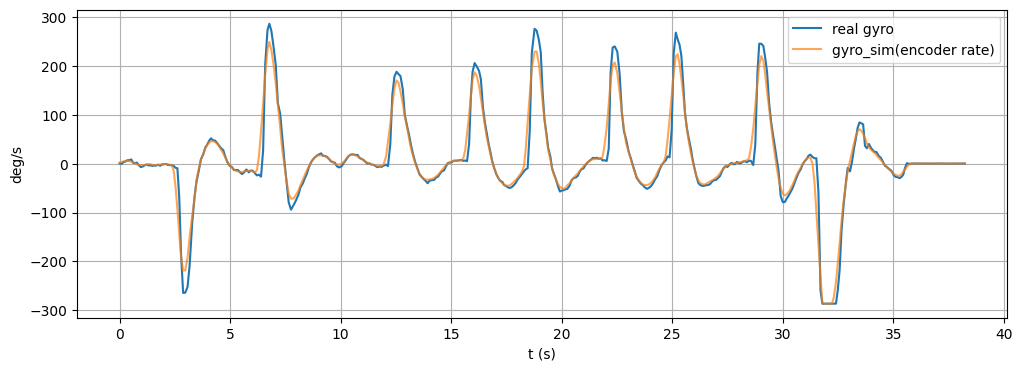

In [12]:
def gyro_sim(omega_true, t, seed=0):
    rng = np.random.default_rng(seed)
    omega_true = np.asarray(omega_true, dtype=float)
    s = np.where(omega_true >= 0, s_ccw, s_cw)     # scale-factor error (CCW / CW)
    out = (1 + s) * omega_true + b0 + d / 60 * t + rng.normal(0, sigma, len(t))   # d: deg/s per min -> per s
    out = np.clip(out, w_max_neg, w_max_pos)        # saturation
    return np.round(out / delta) * delta            # quantisation

w_sim = gyro_sim(enc_rate, tr)
plt.figure(figsize=(12, 4))
plt.plot(tr, w_rot, label='real gyro')
plt.plot(tr, w_sim, alpha=0.7, label='gyro_sim(encoder rate)')
plt.xlabel('t (s)'); plt.ylabel('deg/s'); plt.legend(); plt.grid(True); plt.show()

## Parameter table

In [13]:
table = pd.DataFrame([
    ['Offset (bias)', 'b0', b0, 'deg/s', f'static mean, outliers removed, T = {T_cal} s'],
    ['Bias drift', 'd', d, 'deg/s/min', '30-s window means'],
    ['Heading drift, uncorrected', '', slope_a, 'deg/min', 'slope of theta(t)'],
    ['Measurement range', '+-w_max', f'+{w_max_pos:.1f} / {w_max_neg:.1f}', 'deg/s', 'saturation test (robot run + hand spin); see §3 for which side is observed'],
    ['Resolution', 'Delta', delta, 'deg/s', 'quantisation step'],
    ['Noise std', 'sigma', sigma, 'deg/s', 'static, 3 min'],
    ['Raw -> deg/s factor', '', raw_factor, '-', 'documented unit of read()[2] (not measured, readRawData() not logged)'],
    ['Scale-factor error CCW / CW', 's', f'{s_ccw*100:.2f} / {s_cw*100:.2f}', '%', 'gyro vs encoder angle'],
    ['Positive rotation direction', '', positive_dir, '-', 'sign check'],
], columns=['Parameter', 'Symbol', 'Value', 'Unit', 'Method'])
table

,Parameter,Symbol,Value,Unit,Method
0,Offset (bias),b0,0.456147,deg/s,"static mean, outliers removed, T = 10 s"
1,Bias drift,d,-0.006733,deg/s/min,30-s window means
2,"Heading drift, uncorrected",,25.680248,deg/min,slope of theta(t)
3,Measurement range,+-w_max,+286.5 / -286.4,deg/s,saturation test (robot run + hand spin); see §...
4,Resolution,Delta,0.00876,deg/s,quantisation step
5,Noise std,sigma,0.075707,deg/s,"static, 3 min"
6,Raw -> deg/s factor,,0.001,-,"documented unit of read()[2] (not measured, re..."
7,Scale-factor error CCW / CW,s,11.99 / 8.98,%,gyro vs encoder angle
8,Positive rotation direction,,CCW,-,sign check


Heading error from each source after 10 s, 1 min and 3 min (helps for the analysis).

In [14]:
rot_rate = np.mean(np.abs(enc_rate))                # typical turning rate in this run, deg/s
rows = []
for T in (10, 60, 180):
    rows.append({'time': f'{T} s',
                 'bias not removed: b0*T (deg)': abs(b0) * T,
                 'bias left after calibrate_gyro (deg)': abs(np.interp(T, ts, theta_b)),
                 'drift: d/60*T^2/2 (deg)': abs(d) / 60 * T**2 / 2,
                 'noise: sigma*sqrt(dt*T) (deg)': sigma * np.sqrt(np.mean(np.diff(ts)) * T),
                 'scale factor: |s|*rate*T (deg)': max(abs(s_ccw), abs(s_cw)) * rot_rate * T})
pd.DataFrame(rows).round(3)

,time,bias not removed: b0*T (deg),bias left after calibrate_gyro (deg),drift: d/60*T^2/2 (deg),noise: sigma*sqrt(dt*T) (deg),scale factor: |s|*rate*T (deg)
0,10 s,4.561,0.013,0.006,0.071,53.874
1,60 s,27.369,0.480,0.202,0.175,323.244
2,180 s,82.106,4.326,1.818,0.303,969.731


## Short analysis (≤ 1 page)
*Numbers marked ⟨…⟩ come from the cells above after rerunning; fill them in from your outputs.*

**Data.** Option B: the go-to-goal path "70" plus one more lap of the "0" (9 turns ≥ 90°). The gyro timestamp `read()[3]` counts in 256 µs ticks, not µs. The logging loop ran at about 89 ms per sample instead of the intended 10 ms, so at the fastest turns the robot rotates about 25° between samples; σ and R below are valid only at this interval. The rate was logged with `read()[2]` (mdeg/s), not `readRawData()`, so the raw → deg/s factor was not measured.

**Parameters.**
- Bias b0 = ⟨b0⟩ deg/s from `calibrate_gyro` (first 10 s). Uncorrected, the heading drifts about 26 deg/min.
- The bias drifts: d ≈ ⟨d⟩ deg/s/min, i.e. it falls by about 0.04 deg/s over the 3 min even after the 2-min warm-up.
- Noise σ ≈ 0.076 deg/s at 89 ms, Gaussian-looking histogram with ⟨n⟩ samples beyond 4σ.
- Resolution Δ ≈ 8.76 mdeg/s, consistent with the 8.75 mdps/LSB of a ±250 dps MEMS gyro.
- Range: the negative side saturates at −286.4 deg/s (repeated value, ⟨n⟩ samples, ⟨robot/hand⟩). The positive side reached +286.5 deg/s only once, so +ω_max is inferred by symmetry (32767 × 8.75 mdeg/s ≈ 286.7 deg/s), not observed as a flat top.
- Scale factor: the gyro reports more rotation than the encoders, s CCW ≈ +12 %, s CW ≈ +9 %. It depends on speed: slow turns ≈ +14–15 %, sharp turns ≈ +7–12 %. Part of the drop on sharp turns, especially CW, is the gyro clipping at −286 deg/s, which under-reports the turn.

**Gyro or encoders?** At the end of the run the gyro and encoder headings differ by about 55°. Floor-mark angle: ⟨…⟩ deg, so the ⟨gyro / encoder⟩ is closer to the truth. Wheel slip alone would make the encoders *over*-report rotation (s negative), so a positive s points to the effective track width of the skid-turning robot being smaller than 15.4 cm, or to a real gain error of the gyro. The floor mark decides which.

**Dominant error source.**
- After **10 s** of driving: the scale factor (≈ 54° at the typical turning rate, vs ≈ 4° from an uncorrected bias).
- After **1 min** and **3 min** with turns: still the scale factor; an uncorrected bias adds a steady 26 deg/min on top.
- Standing still: only the bias and its drift; the bias drift gives the ⟨…⟩° residual after 3 min shown below.
- Saturation adds error only on the fastest turns.

**Calibration method.** `calibrate_gyro()` takes the first 10 s of the static log, rejects samples more than 3·MAD from the median, and returns the mean of the rest. The b0(T) curve settles to within about 0.02 deg/s after 10 s. Tested on the full 3-min static log, it leaves ⟨…⟩° after 1 min and ⟨…⟩° after 3 min. Because the bias keeps drifting, a 10-s calibration leaves an error that grows with time; the T_cal table shows how much a longer calibration (or a longer warm-up) would remove.
